# Development of the learned weight matrix: full-batch learning

**Julian Hoyer's experiment.** Every matrix in this notebook follows the same
$\lambda=1$, noise-free **full-batch** gradient-descent trajectory as
`power_law.ipynb`. Each learning step averages over **all 500 angles**.
Steps 1–10 are evaluated directly; saved power-law matrices supply all later
checkpoints through $10^9$. The two calculations agree at their shared early
checkpoints, as checked below. All plots and tables are embedded.

The layouts follow Clark et al.'s Figure 2a,b: rows are receiving neurons,
columns are sending neurons, and a diverging map distinguishes negative and
positive weights. The paper reference is computed on the same input realization
with the paper's ridge coefficient $10^{-8}$; full-batch learning has no explicit
weight penalty.

At $\lambda=1$, $x_i(\theta)=h_i(\theta)$ at every step. Changing $J$ changes
the prediction $p_i$, not the clamped tuning curves. The circular COM is computed
from the complete firing-rate curve:

\[
\mu_i^{(n)}=\arg\!\left[\sum_\theta
\phi(x_i^{(n)}(\theta))e^{i\theta}\right]\pmod{2\pi}.
\]

COM and its permutation are recomputed at every displayed checkpoint and stay
unchanged under this clamped condition. Sorting uses the original repository's
COM convention. No source model, saved training weights, `ring/`, `data/` or
power-law results are modified. New figures and tables are saved only to
`notebooks/weight_development_outputs/`.

In [1]:
import hashlib
import json
import os
import sys
from io import BytesIO
from pathlib import Path

sys.dont_write_bytecode = True
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import numpy as np
import pandas as pd
import torch
from matplotlib.figure import Figure
from matplotlib.colors import Normalize
from IPython.display import Image, display
from PIL import Image as PILImage

here = Path.cwd().resolve()
parents = [here, *here.parents]
candidates = parents + [p / '.worktrees/local-learning' for p in parents]
ROOT = next(p for p in candidates if
            (p / 'notebooks/predictive_rule_outputs/full/model.npz').is_file())
sys.path.insert(0, str(ROOT))
from ring import data_driven, fn, style

SOURCE = ROOT / 'notebooks/predictive_rule_outputs/full'
OUT = ROOT / 'notebooks/weight_development_outputs'
OUT.mkdir(exist_ok=True)
config = json.loads((SOURCE / 'config.json').read_text())
with np.load(SOURCE / 'model.npz', allow_pickle=False) as model:
    H, Phi, J_paper = model['H'].copy(), model['Phi'].copy(), model['J_paper'].copy()
N, N_theta = config['N'], config['N_theta']
BATCH, ETA0, BETA = N_theta, config['eta0'], config['beta']
DEVICE, DTYPE = torch.device(config['device']), torch.float64
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.use_deterministic_algorithms(True)

def nonlin(x):
    return fn.nonlin_idealized(x, BETA)

def show_figure(fig, filename, dpi=145, preview_size=(1100, 1100)):
    path = OUT / filename
    fig.savefig(path, dpi=dpi)
    with PILImage.open(path) as image:
        preview = image.convert('RGB')
        preview.thumbnail(preview_size)
        preview = preview.quantize(colors=256)
        buffer = BytesIO()
        preview.save(buffer, format='PNG', optimize=True)
    display(Image(data=buffer.getvalue()))

print(f'Full-batch GD: lambda = 1; noise = 0; N = {N}; all {BATCH} angles per step; eta0 = {ETA0}.')
print('Generated figures and tables:', OUT)

Full-batch GD: lambda = 1; noise = 0; N = 1000; all 500 angles per step; eta0 = 0.5.
Generated figures and tables: /Users/julianhoyer/Documents/symmetries-continuous-attractors/.worktrees/local-learning/notebooks/weight_development_outputs


## Direct full-batch steps 1–10 and saved power-law checkpoints

The full-batch rule is
\[
\Delta J=\frac{\eta_0}{NN_\theta}(H^T-J\Phi^T)\Phi,
\qquad J\leftarrow J+\Delta J,\quad J_{ii}\leftarrow0.
\]

Ten direct updates supply the first ten matrices. Their shared checkpoints at
steps 1, 2 and 10 must agree with the saved closed-form weights within $10^{-12}$
relative Frobenius distance. All subsequent requested checkpoints are loaded
from the power-law cache, without rerunning its SVDs or long training.

In [2]:
long_root = ROOT / 'notebooks/power_law_outputs'
long_config = json.loads((long_root / 'experiment.json').read_text())
assert long_config['model_sha256'] == hashlib.sha256((SOURCE / 'model.npz').read_bytes()).hexdigest(), \
       'The power-law run must use exactly the same tuning curves.'
assert long_config['eta0'] == ETA0
long_weights = np.load(long_root / 'closed_form_weights.npy', mmap_mode='r')
cached_index = {int(step): index for index, step in enumerate(long_config['all_cached_steps'])}

H_t = torch.as_tensor(H, dtype=DTYPE, device=DEVICE)
Phi_t = torch.as_tensor(Phi, dtype=DTYPE, device=DEVICE)
J = torch.zeros((N, N), dtype=DTYPE, device=DEVICE)
snapshots = {0: J.cpu().numpy().copy()}
validation_rows = []
with torch.no_grad():
    for step in range(1, 11):
        J.add_((H_t.T - J @ Phi_t.T) @ Phi_t, alpha=ETA0 / (N * N_theta))
        J.fill_diagonal_(0)
        snapshots[step] = J.cpu().numpy().copy()
        if step in cached_index:
            cached = np.asarray(long_weights[cached_index[step]])
            relative_error = np.linalg.norm(snapshots[step]-cached) / np.linalg.norm(cached)
            assert relative_error < 1e-12
            validation_rows.append(dict(step=step, relative_frobenius_distance=relative_error))
validation_table = pd.DataFrame(validation_rows)
validation_table.to_csv(OUT / 'full_batch_checkpoint_validation.csv', index=False)
display(validation_table)
print('PASS: direct full-batch updates match the saved power-law trajectory.')

for step in long_config['requested_steps']:
    if step > 10:
        snapshots[int(step)] = np.array(long_weights[cached_index[int(step)]], copy=True)
STEPS = sorted(snapshots)
assert STEPS == list(range(11)) + [30, 100, 300, 1000, 3000, 10000, 30000,
                                  100000, 300000, 1000000, 10000000, 100000000, 1000000000]
assert all(np.isfinite(matrix).all() and np.all(matrix.diagonal() == 0)
           for matrix in snapshots.values())
print('Displayed full-batch learning steps:', STEPS)

,step,relative_frobenius_distance
0,1,5.917025e-15
1,2,5.329340e-15
2,10,3.745688e-15


PASS: direct full-batch updates match the saved power-law trajectory.
Displayed full-batch learning steps: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 30, 100, 300, 1000, 3000, 10000, 30000, 100000, 300000, 1000000, 10000000, 100000000, 1000000000]


## Recalculate COM and fix the color scale

The same permutation is applied to rows and columns. To match the original
figure's implementation, angular COMs are converted to angular-bin indices before
sorting. Both signs use one color scale across every checkpoint and the paper
reference. The limit is the larger 99th percentile of absolute weights in the
final learned matrix and paper matrix; rarer extremes saturate. No matrix is
normalized separately, so the growth of weight amplitude remains visible.

In [3]:
orders, coms = {}, {}
rows, com_rows = [], []
reference_com = data_driven.circular_com(Phi.T)
COLOR_LIMIT = max(float(np.quantile(np.abs(snapshots[STEPS[-1]]), .99)),
                  float(np.quantile(np.abs(J_paper), .99)))
NORM = Normalize(vmin=-COLOR_LIMIT, vmax=COLOR_LIMIT)
CMAP = style.DIVERGING_CMAP
paper_norm = np.linalg.norm(J_paper)
for step in STEPS:
    # Full theta-conditioned somatic responses at this checkpoint. They remain
    # H under lambda=1, even though the recurrent prediction changes with J.
    x_curves = H.copy()
    firing_curves = nonlin(x_curves)
    np.testing.assert_allclose(firing_curves, Phi, rtol=0, atol=0)
    coms[step] = data_driven.circular_com(firing_curves.T)
    _, orders[step] = data_driven.sort_weight_matrix(snapshots[step], firing_curves)
    change = np.rad2deg(np.angle(np.exp(1j * (coms[step] - reference_com))))
    matrix = snapshots[step]
    rows.append(dict(step=step, weight_rms=float(np.sqrt(np.mean(matrix**2))),
                     weight_norm=float(np.linalg.norm(matrix)),
                     relative_distance_from_paper=float(np.linalg.norm(matrix-J_paper)/paper_norm),
                     fraction_color_saturated=float(np.mean(np.abs(matrix) > COLOR_LIMIT)),
                     maximum_com_change_deg=float(np.max(np.abs(change)))))
    inverse_order = np.argsort(orders[step])
    com_rows.extend(dict(step=step, neuron=i+1, com_deg=float(np.rad2deg(coms[step][i])),
                         sorted_rank=int(inverse_order[i])+1) for i in range(N))

summary = pd.DataFrame(rows)
summary.to_csv(OUT / 'checkpoint_summary.csv', index=False)
pd.DataFrame(com_rows).to_csv(OUT / 'com_at_each_checkpoint.csv', index=False)
assert summary.maximum_com_change_deg.max() < 1e-10
assert all(np.array_equal(orders[step], orders[0]) for step in STEPS)
paper_sorted, paper_order = data_driven.sort_weight_matrix(J_paper, Phi)
assert np.array_equal(paper_order, orders[0])
print(f'COM recomputed at {len(STEPS)} checkpoints; maximum change = {summary.maximum_com_change_deg.max():.3g} degrees.')
print(f'Common color limits: {-COLOR_LIMIT:.6g} to {COLOR_LIMIT:.6g}.')
display(summary)

COM recomputed at 24 checkpoints; maximum change = 0 degrees.
Common color limits: -0.00864126 to 0.00864126.


,step,weight_rms,weight_norm,relative_distance_from_paper,fraction_color_saturated,maximum_com_change_deg
0,0,0.000000,0.000000,1.000000,0.000000,0.0
1,1,0.000319,0.318566,0.953618,0.000000,0.0
2,2,0.000488,0.488464,0.918373,0.000000,0.0
3,3,0.000603,0.603311,0.887191,0.000000,0.0
4,4,0.000699,0.698576,0.858603,0.000000,0.0
5,5,0.000786,0.786405,0.832188,0.000000,0.0
6,6,0.000870,0.870369,0.807727,0.000000,0.0
7,7,0.000951,0.951213,0.785047,0.000000,0.0
8,8,0.001029,1.028905,0.763998,0.000000,0.0
9,9,0.001103,1.103293,0.744440,0.000000,0.0


In [4]:
def matrix_at(step, sorted_by_com=False):
    if step == 'paper':
        return paper_sorted if sorted_by_com else J_paper
    matrix = snapshots[step]
    if sorted_by_com:
        order = orders[step]
        matrix = matrix[np.ix_(order, order)]
    return matrix

def draw_matrix(ax, matrix, title, sorted_by_com):
    image = ax.imshow(matrix, norm=NORM, cmap=CMAP, interpolation='nearest',
                      origin='upper', rasterized=True)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([0, N-1], ['1', str(N)])
    ax.set_yticks([0, N-1], ['1', str(N)])
    ax.tick_params(labelsize=7)
    ax.set_xlabel('Presynaptic COM rank' if sorted_by_com else 'Presynaptic neuron j', fontsize=8)
    ax.set_ylabel('Postsynaptic COM rank' if sorted_by_com else 'Postsynaptic neuron i', fontsize=8)
    ax.set_aspect('equal')
    return image

def grid_figure(steps, sorted_by_com, title, filename):
    columns = 4
    nrows = (len(steps) + columns - 1) // columns
    fig = Figure(figsize=(12, 3.05*nrows + .6), layout='constrained')
    axes = fig.subplots(nrows, columns, squeeze=False)
    for ax, step in zip(axes.flat, steps):
        label = 'Paper reference' if step == 'paper' else f'Step {step:,}'
        im = draw_matrix(ax, matrix_at(step, sorted_by_com), label, sorted_by_com)
    for ax in list(axes.flat)[len(steps):]:
        ax.set_visible(False)
    fig.colorbar(im, ax=list(axes.flat)[:len(steps)], shrink=.7, fraction=.025,
                 label='Jij (same scale at every step)', extend='both')
    fig.suptitle(title, fontsize=13)
    show_figure(fig, filename)

## First ten full-batch updates: original neuronal order

Step 0 shows the zero initialization; steps 1–10 show every full-batch update.
The final panel is the paper reference on the same input realization and scale.

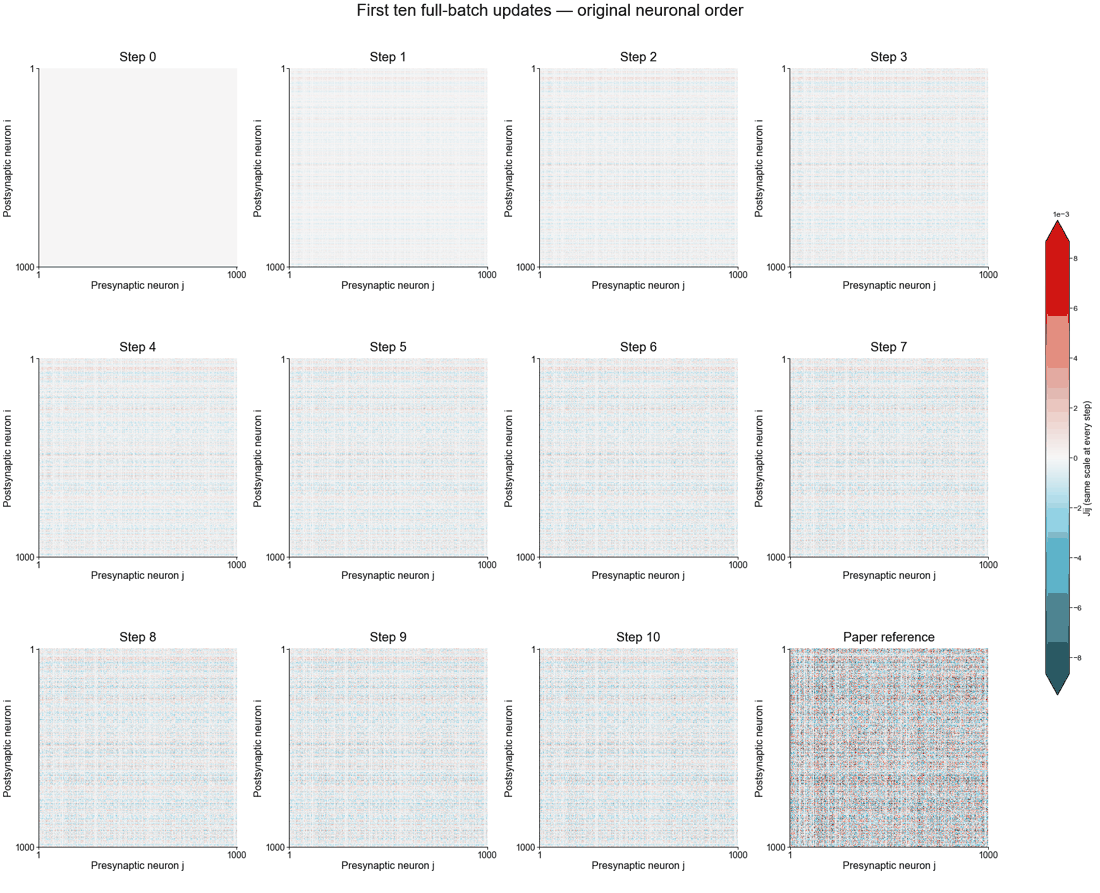

In [5]:
EARLY = list(range(11)) + ['paper']
grid_figure(EARLY, False, 'First ten full-batch updates — original neuronal order', 'first_10_original.png')

## First ten full-batch updates: COM-sorted order

COM is recalculated from the full clamped tuning curves at every displayed step.
The order remains identical; changes in these panels are changes in J.

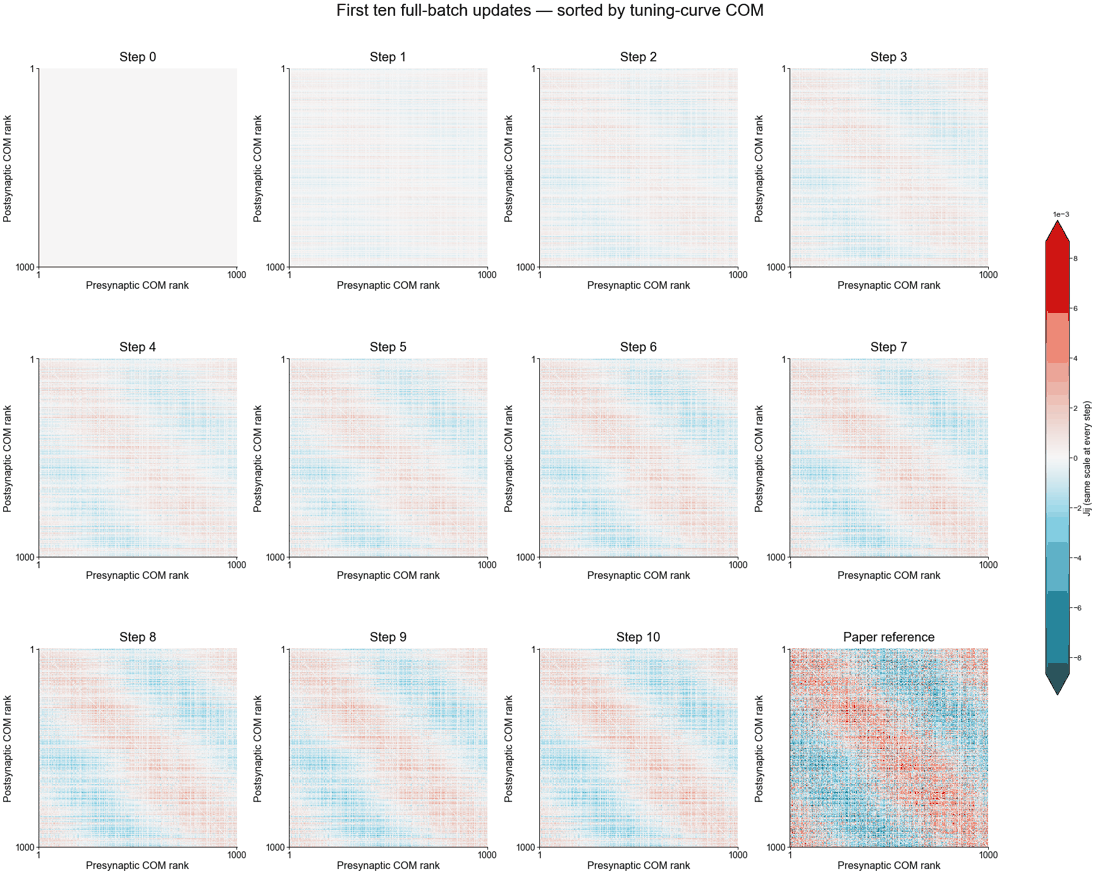

In [6]:
grid_figure(EARLY, True, 'First ten full-batch updates — sorted by tuning-curve COM', 'first_10_com_sorted.png')

## Later full-batch checkpoints: original neuronal order

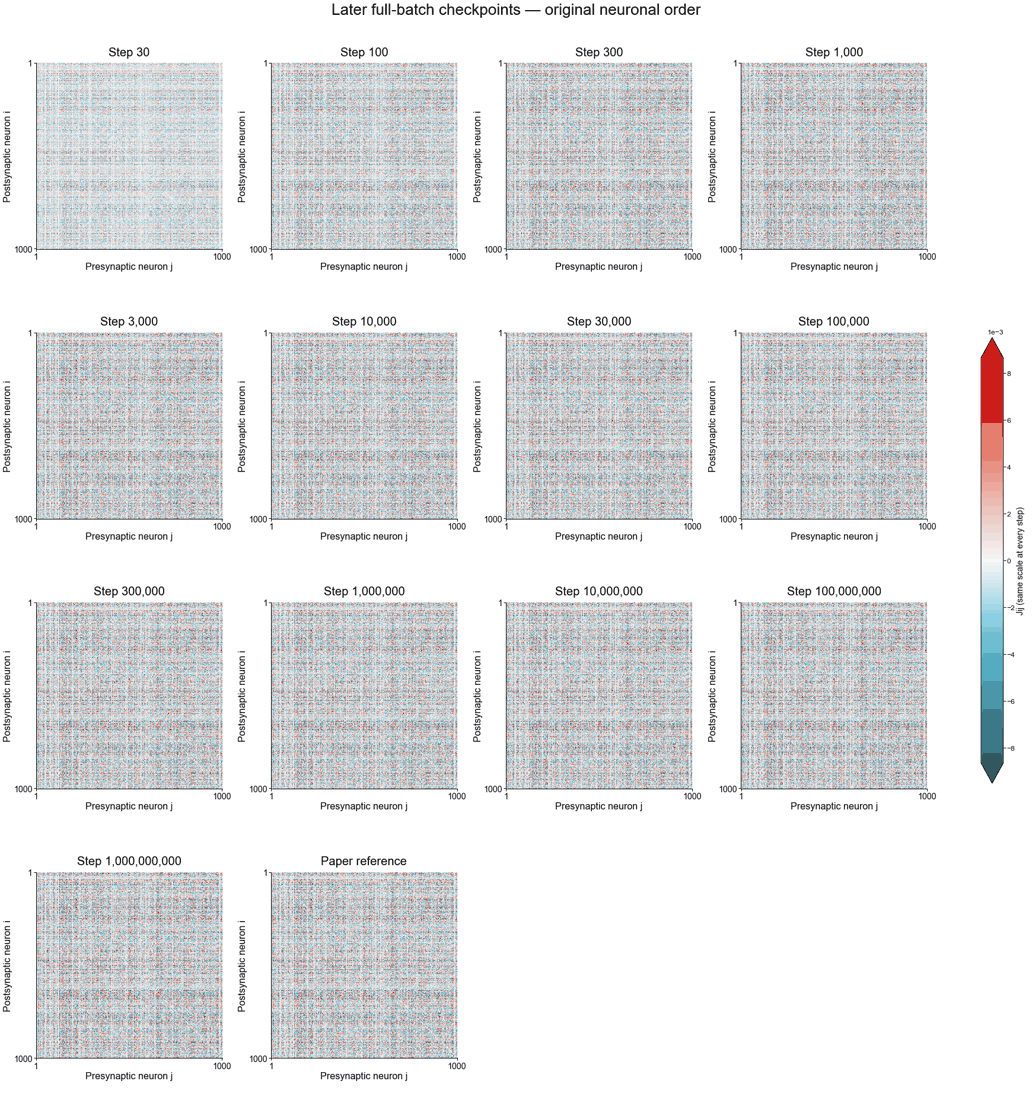

In [7]:
LATER = [step for step in STEPS if step > 10] + ['paper']
grid_figure(LATER, False, 'Later full-batch checkpoints — original neuronal order', 'later_original.png')

## Later full-batch checkpoints: COM-sorted order

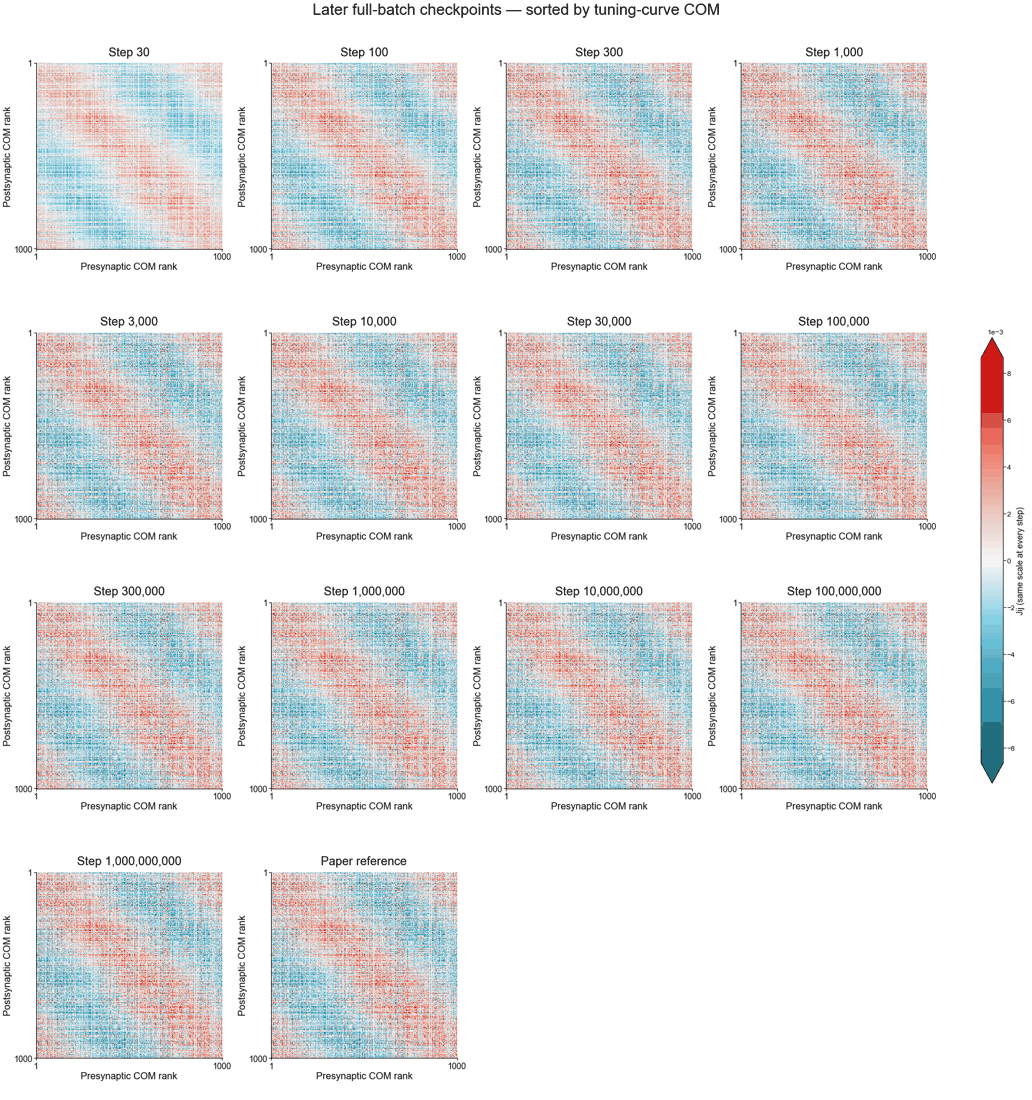

In [8]:
grid_figure(LATER, True, 'Later full-batch checkpoints — sorted by tuning-curve COM', 'later_com_sorted.png')

## Final full-batch matrix beside the paper reference

The columns correspond to Figure 2a,b: arbitrary order on the left and COM order
on the right. The upper row is full-batch GD at 1,000,000,000 steps from the
power-law cache; the lower row is the analytical paper reference.

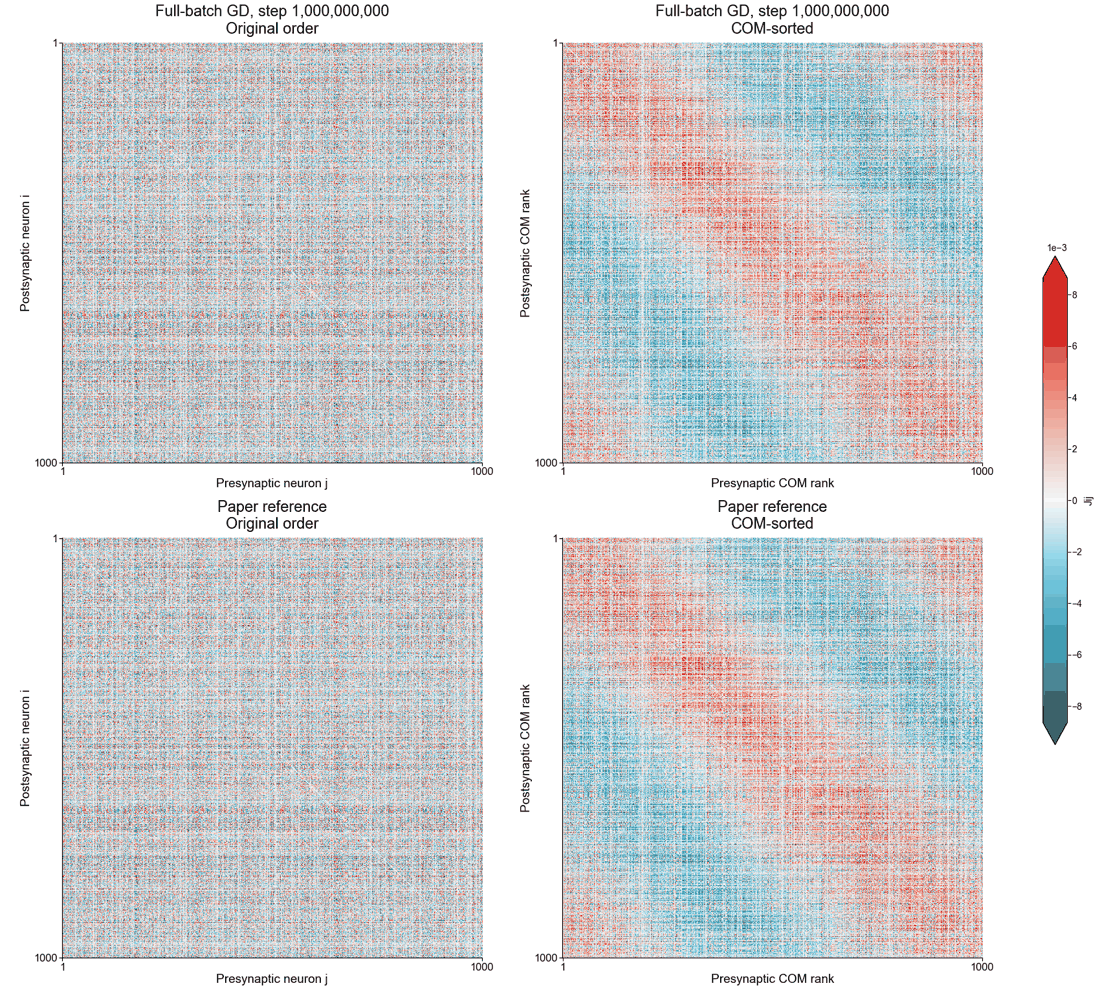

In [9]:
fig = Figure(figsize=(10, 9), layout='constrained')
axes = fig.subplots(2, 2)
for row, step in enumerate([STEPS[-1], 'paper']):
    name = f'Full-batch GD, step {step:,}' if step != 'paper' else 'Paper reference'
    for col, sorted_by_com in enumerate([False, True]):
        order_label = 'COM-sorted' if sorted_by_com else 'Original order'
        im = draw_matrix(axes[row, col], matrix_at(step, sorted_by_com),
                         f'{name}\n{order_label}', sorted_by_com)
fig.colorbar(im, ax=list(axes.flat), shrink=.7, fraction=.025, label='Jij', extend='both')
show_figure(fig, 'final_and_paper.png', dpi=170)

## Relative Frobenius distance to the paper reference

The comparison uses only $J_{\mathrm{paper}}$, computed on the same tuning
curves with the paper's regularization coefficient $10^{-8}$:

\[
\text{Relative Frobenius distance}
=\frac{\|J^{(n)}-J_{\mathrm{paper}}\|_F}{\|J_{\mathrm{paper}}\|_F}.
\]

All 23 nonzero checkpoints follow the same full-batch trajectory: steps 1–10
and every later requested power-law checkpoint, through $10^9$. In particular,
the final three checkpoints show the approach to the sampled distance minimum
at $10^8$ and its subsequent increase at $10^9$.

In [10]:
COMPARISON_STEPS = [step for step in STEPS if step != 0]
comparison_panels = [('Full-batch GD', step, snapshots[step]) for step in COMPARISON_STEPS]
assert len(comparison_panels) == 23

metric_rows = []
for training, step, matrix in comparison_panels:
    difference_norm = float(np.linalg.norm(J_paper-matrix))
    metric_rows.append(dict(training=training, step=step,
                            frobenius_norm_of_difference=difference_norm,
                            relative_frobenius_distance_to_paper=difference_norm/paper_norm))
difference_metrics = pd.DataFrame(metric_rows)
difference_metrics.to_csv(OUT / 'matrix_difference_metrics.csv', index=False)
display(difference_metrics)

power_law_metrics = pd.read_csv(long_root / 'metrics.csv')
expected = power_law_metrics[power_law_metrics.method == 'closed_form_gd'].set_index('step')
observed = difference_metrics.set_index('step')
shared = expected.index.intersection(observed.index)
np.testing.assert_allclose(observed.loc[shared, 'relative_frobenius_distance_to_paper'],
                           expected.loc[shared, 'relative_weight_error'], rtol=1e-12, atol=1e-14)
long_distances = observed.loc[[10_000_000, 100_000_000, 1_000_000_000],
                               'relative_frobenius_distance_to_paper'].to_numpy()
assert long_distances[1] < long_distances[0] and long_distances[2] > long_distances[1]
print('PASS: Frobenius distances agree with the power-law results at every shared checkpoint.')

,training,step,frobenius_norm_of_difference,relative_frobenius_distance_to_paper
0,Full-batch GD,1,2.967919,0.953618
1,Full-batch GD,2,2.858226,0.918373
2,Full-batch GD,3,2.761178,0.887191
3,Full-batch GD,4,2.672206,0.858603
4,Full-batch GD,5,2.589996,0.832188
5,Full-batch GD,6,2.513865,0.807727
6,Full-batch GD,7,2.443280,0.785047
7,Full-batch GD,8,2.377768,0.763998
8,Full-batch GD,9,2.316899,0.744440
9,Full-batch GD,10,2.260277,0.726247


PASS: Frobenius distances agree with the power-law results at every shared checkpoint.


## COM-sorted full-batch differences, including the long-run upturn

Every panel shows $J_{\mathrm{paper}}-J_{\mathrm{learned}}^{(n)}$ in the common
COM order, with its **relative Frobenius distance** printed above it. The
entire figure uses one full-batch learning trajectory and one fixed zero-centered
color scale. The distance increases between $10^8$ and $10^9$ steps.

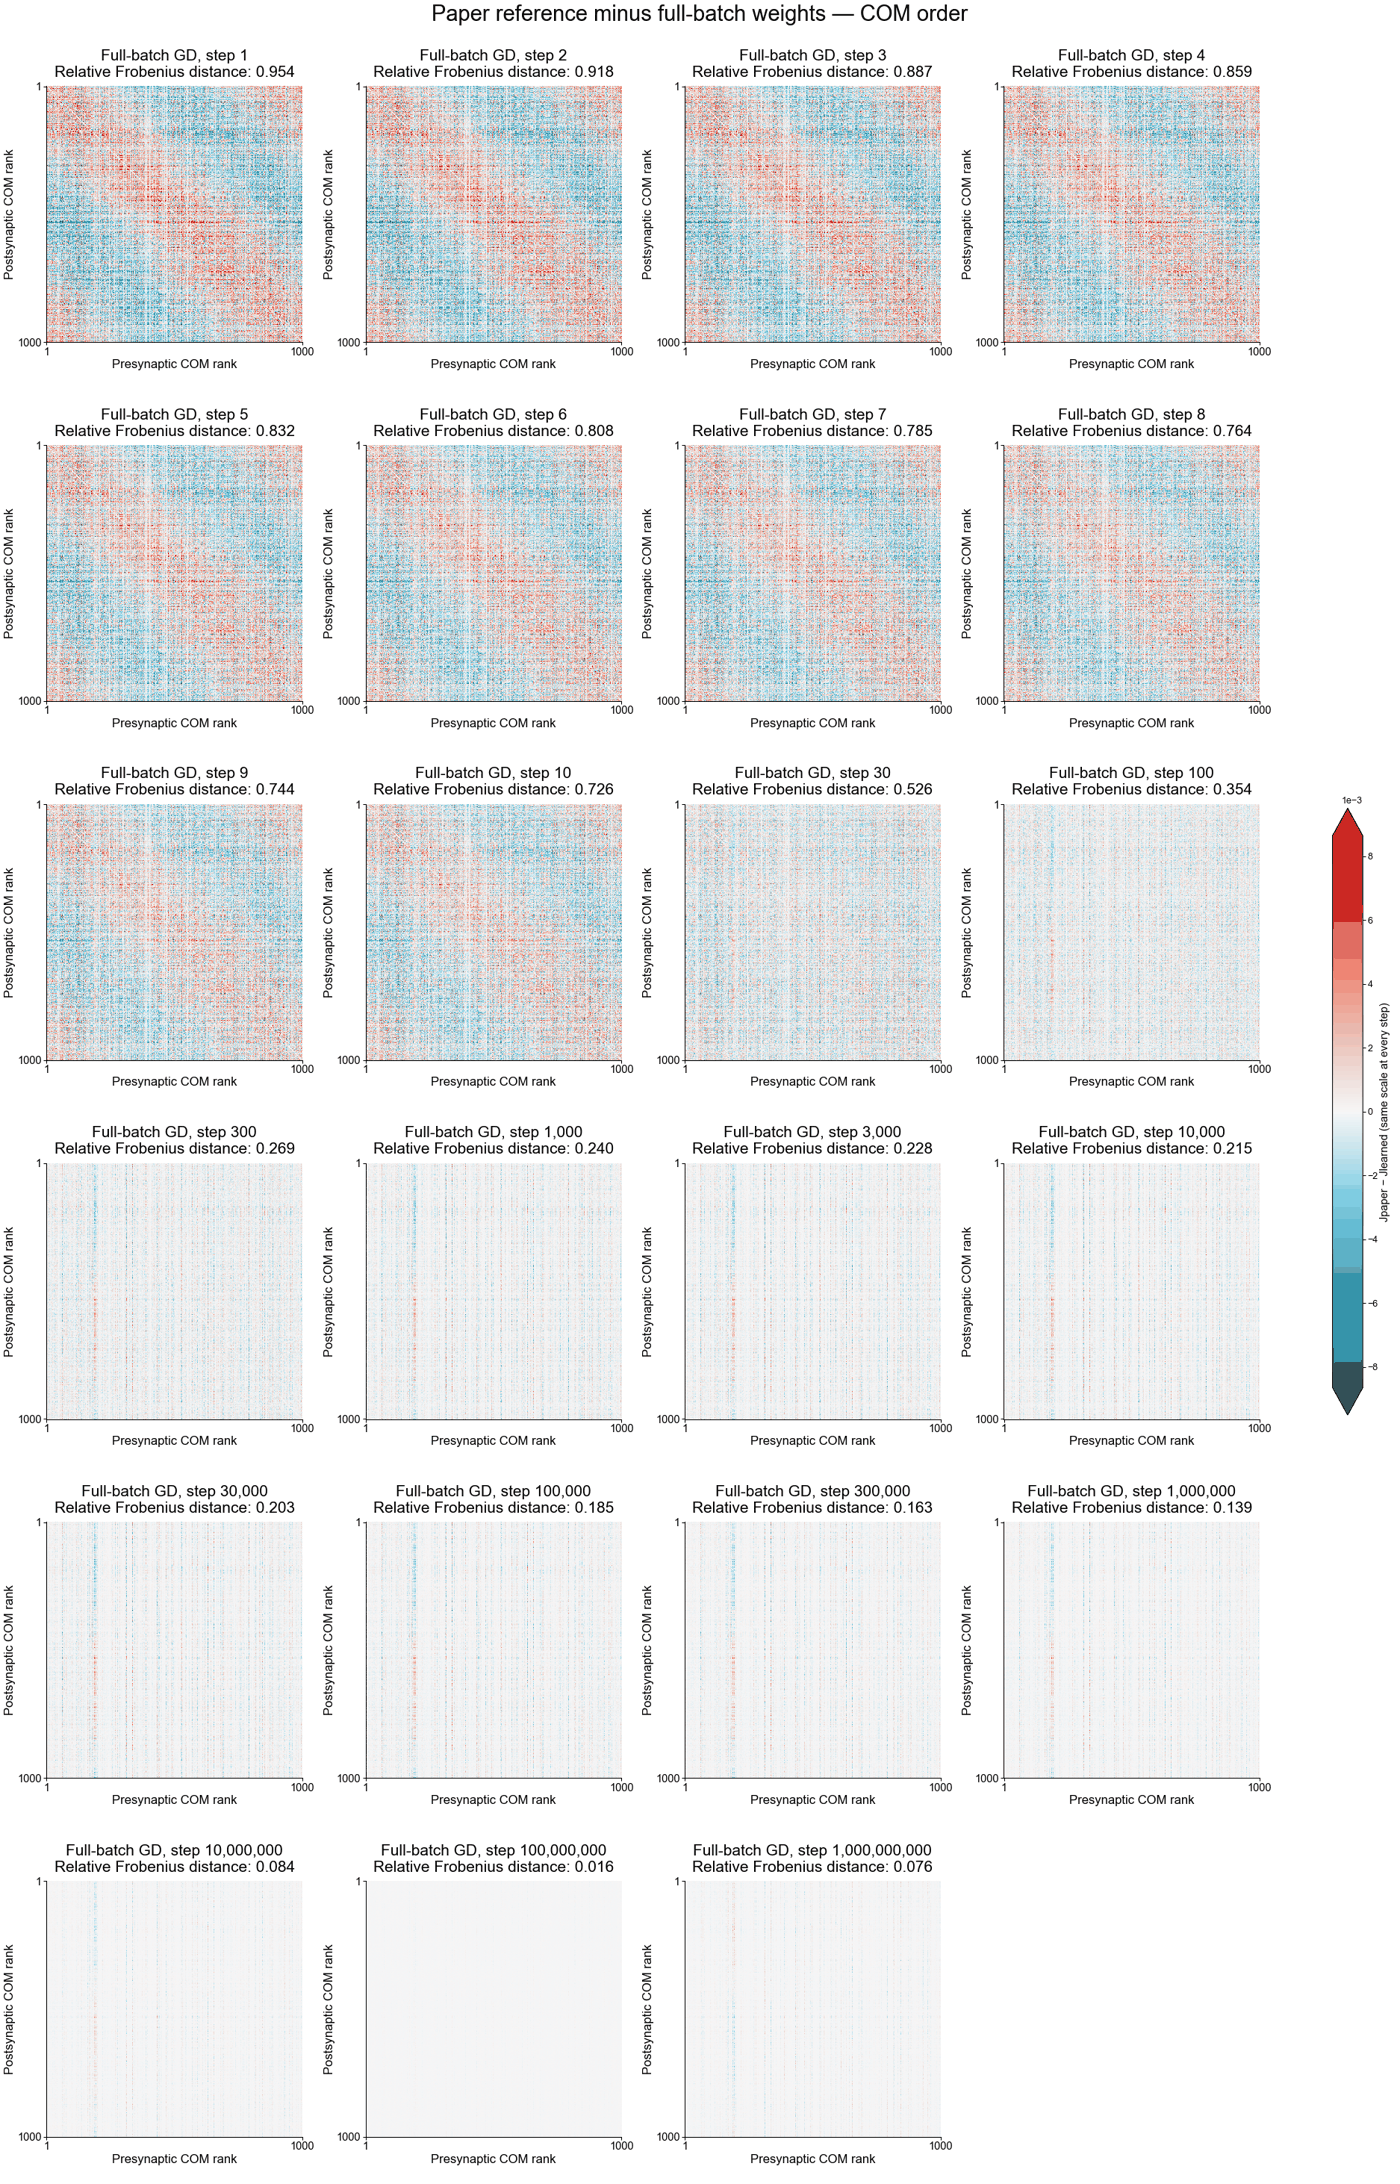

In [11]:
columns = 4
number_rows = (len(comparison_panels) + columns - 1) // columns
fig = Figure(figsize=(12.5, 3.15 * number_rows + .6), layout='constrained')
axes = fig.subplots(number_rows, columns, squeeze=False)
used_axes = []
for index, (training, step, matrix) in enumerate(comparison_panels):
    ax = axes.flat[index]
    difference = J_paper - matrix
    order = orders[0]
    sorted_difference = difference[np.ix_(order, order)]
    np.testing.assert_array_equal(sorted_difference,
                                  paper_sorted - matrix[np.ix_(order, order)])
    distance = difference_metrics.iloc[index].relative_frobenius_distance_to_paper
    step_label = f'{step:,}'
    title = f'{training}, step {step_label}\nRelative Frobenius distance: {distance:.3f}'
    im = draw_matrix(ax, sorted_difference, title, sorted_by_com=True)
    used_axes.append(ax)
for ax in list(axes.flat)[len(comparison_panels):]:
    ax.set_visible(False)
fig.colorbar(im, ax=used_axes, shrink=.6, fraction=.025,
             label='Jpaper − Jlearned (same scale at every step)', extend='both')
fig.suptitle('Paper reference minus full-batch weights — COM order', fontsize=14)
show_figure(fig, 'paper_minus_learned_all_steps.png', dpi=150, preview_size=(1400, 2200))